# CausalBridges-03 — Le contrefactuel individuel : quand l'effet moyen cache tout

> Renumerotation #17421 : ce carnet etait publie sous le nom DoWhy-2 ; les renvois internes de la serie citent desormais le numero courant.

**Série** : Inférence causale avec DoWhy (Probas, Python)
**Prérequis** : [CausalBridges-02-Estimand-et-Intervention](CausalBridges-02-Dowhy-Estimand-Intervention.ipynb) 
(l'estimand, le do-calcul, l'ATE) et [Do-Calculus-Bridge](CausalBridges-01-Do-Calculus.ipynb) (backdoor).

**Objet** : monter d'un cran sur l'échelle de Pearl. CausalBridges-02 répondait a la question
« *le traitement a-t-il un effet moyen ?* » (l'**ATE**). Ce notebook pose la question
d'individu : « *que se serait-il passé pour CET étudiant, sans le traitement ?* » — le
**contrefactuel individuel**.


## 1. Le problème — un programme dont l'effet moyen vaut zéro

Un projet pilote de **mentorat intensif** (`T`) est testé sur des étudiants ; le
**résultat** (`Y`) est la progression au semestre. Chaque étudiant a un trait
**`V`** (autonomie initiale, entre -1 et +1). Le programme est hétérogène :

| Effet | Valeur | Sens |
|---|---|---|
| **ATE** (effet moyen de `do(T:=1)` vs `do(T:=0)`) | **0** | ne dit rien |
| **CATE** `3.V` (effet selon l'autonomie) | **de -3 a +3** | tout dire, en sens inverse |

Pour un étudiant a `V = +1`, le mentorat apporte **+3** points ; pour `V = -1`, il
**en coûte 3**. En moyenne, cela fait zéro — et pourtant, personne n'est moyen.
L'**ATE** est honnête mais aveugle : il faut descendre a l'échelle de l'individu.

Ce notebook fait ce que CausalBridges-02 ne pouvait pas : utiliser la **structure du SCM
appris** pour rejouer le monde d'un individu sous une autre intervention
(abduction, action, prediction).


## 2. Le monde génératif — de l'hétérogénéité qui s'annule en moyenne

Le générateur (vérité du monde, invisible du modèle) :

| Variable | Equation | Role |
|---|---|---|
| `V` | `V ~ U(-1, 1)` | modificateur d'effet (racine) |
| `T` | `T = 0.5 + 0.3 V + N(0, 0.2)` | traitement (confondu par `V`) |
| `Y` | `Y = 1 + 3.T.V + 0.5 V + N(0, 0.5)` | résultat (l'interaction `T.V` porte l'hétérogénéité) |

L'effet individuel d'un changement de traitement est `3.T.V` : positif pour `V > 0`,
négatif pour `V < 0`, de moyenne `3.E[T.V] = 0.3` — **petit en moyenne, énorme en
extrême**. Attention, conflit de définition : l'**ATE** canonique
`E[Y(T:=1) - Y(T:=0)] = 3.E[V] = 0`. Les deux chiffres (0.3 et 0) racontent la
même histoire : la moyenne est minuscule, la dispersion est la vraie information.


In [1]:
%matplotlib inline
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Acceptance #14049 slice 1/4 : import depuis dowhy_organs (module canonique)
from dowhy_organs import (
    generer_donnees, construire_scm, contrefactuel_individuel, ecarts_contrefactuels, BETA_INTERACTION,
)

donnees = generer_donnees(n=600, seed=42)
print(donnees.head().round(3))

# Premier nombre : la regression naive Y ~ T, aveugle au confondant V
pente_naive = float(np.polyfit(donnees["T"], donnees["Y"], 1)[0])
print(f"Pente naive Y ~ T (confondue) : {pente_naive:+.3f}")


       V      T      Y
0 -0.251  0.319  0.360
1  0.901  0.612  2.770
2  0.464  0.618  2.079
3  0.197  0.352  1.893
4 -0.688  0.183  0.550
Pente naive Y ~ T (confondue) : +3.077


### 3a. La confusion est déjà lisible à l'œil nu dans la table brute

Avant toute régression, les cinq lignes imprimées montrent le mécanisme en action. Classez-les par `V` : −0,688 → 0,901. La colonne `T` suit : 0,183 → 0,612. L'équation générative `T = 0,5 + 0,3·V + N(0, 0,2)` se vérifie ligne à ligne — pour la ligne 1, l'espérance conditionnelle vaut `0,5 + 0,3 × 0,901 = 0,77`, l'observé 0,612 ; pour la ligne 4, `0,5 + 0,3 × (−0,688) = 0,29` contre 0,183. Les autonomes sont plus traités : **le biais de confusion n'est pas un concept abstrait, il est visible dans les cinq premières lignes**. (Détail d'humilité : les cinq résidus `T − E[T|V]` sont tous négatifs — un effet de tirage du `head()`, pas une structure ; sur n = 600, la covariance `T-V` revient à sa valeur construite `0,3 × Var(V) = 0,1`.)

In [2]:
# Specification qui CONNAIT la forme : Y ~ 1 + T + V + T.V (rung 1, bien posee)
X = np.column_stack([np.ones(len(donnees)), donnees["T"], donnees["V"], donnees["T"] * donnees["V"]])
beta = np.linalg.lstsq(X, donnees["Y"].values, rcond=None)[0]
a, b_t, b_v, b_tv = beta
print(f"OLS bien specific : T = {b_t:+.3f} | V = {b_v:+.3f} | T x V = {b_tv:+.3f}")
print(f"Observez T x V ~ {BETA_INTERACTION:.0f} : la regression retrouve l'interaction SI on lui donne la forme.")


OLS bien specific : T = +0.111 | V = +0.481 | T x V = +2.959
Observez T x V ~ 3 : la regression retrouve l'interaction SI on lui donne la forme.


### 3b. Confronter les quatre coefficients à la vérité générative — y compris le zéro

La sortie donne `T = +0,111 | V = +0,481 | T x V = +2,959`. Le monde, lui, a été écrit `Y = 1 + 3.T.V + 0,5.V + bruit`. La confrontation coefficient par coefficient :

| coefficient | estimé | vrai |
|---|---|---|
| `T` (effet principal) | **+0,111** | **0** — le monde n'a pas d'effet principal |
| `V` | +0,481 | 0,5 |
| `T x V` | +2,959 | 3 |

La régression bien spécifiée récupère **la vérité entière, zéros compris** : les deux coefficients vivants à 0,02 près, et le coefficient de `T` — le seul que le monde ne possède pas — estimé petit, du même ordre que l'erreur d'échantillonnage d'un coefficient dont la cible est zéro. Ce +0,111 mérite d'être retenu : c'est exactement le nombre que la pente naïve (+3,077) avait **gonflé jusqu'à l'invraisemblance** en lui attribuant tout le travail de `V`.

## 4. Pourquoi cela ne suffit pas — connaître la forme, c'est la tricher un peu

L'estimation précédente est « réussie » parce que le monde est **exactement** de la
forme `T + V + T.V`. Sur un vrai terrain, on ne connaît pas la forme : on la devine,
on la teste, on se trompe. Le SCM, lui, **apprend la mécanique** a partir du graphe
et d'une famille de mécanismes, puis l'utilise pour **rejouer** le monde d'un
individu sous une autre intervention.

| Rung (Pearl) | Question | CausalBridges-02 | CausalBridges-03 |
|---|---|---|---|
| Rung 1 — observation | Que s'est-il passé (avec le traitement) ? | l'estimand | la pente naïve + OLS |
| Rung 2 — intervention | Que se passerait-il si TOUS étaient traités ? | l'ATE, backdoor | l'ATE, décomposition |
| Rung 3 — contrefactuel | Que se serait-il passé pour CET individu SANS traitement ? | — | **ce notebook** |

La mécanique de la rung 3, appliquée par le GCM :

1. **Abduction** : a partir des observations de l'individu, retrouver son bruit individuel 
2. **Action** : forcer le traitement a la valeur contre-factuelle (`T := 0`) ;
3. **Prediction** : re-simuler `Y` avec CE bruit, sous l'intervention.

Condition technique : les mécanismes doivent être **inversibles** (le bruit se
déduit de l'observation) — d'où les `AdditiveNoiseModel` du module `dowhy_organs`,
assortis d'un **`InvertibleStructuralCausalModel`**.


In [3]:
t0 = time.time()
scm = construire_scm(donnees, degre_y=2)
print(f"SCM inversible fitte ({time.time()-t0:.2f}s) :")
print('  V ~ distribution empirique | T ~ lineaire + bruit | Y ~ polynomial deg 2 + bruit')


Fitting causal models:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node V:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node T:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node Y:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node Y: 100%|██████████| 3/3 [00:00<00:00, 117.06it/s]

SCM inversible fitte (0.03s) :
  V ~ distribution empirique | T ~ lineaire + bruit | Y ~ polynomial deg 2 + bruit


## 5. Acte 1 — deux étudiants, deux vérités opposées

Parmi les étudiants **traités** (`T > 0.6`), prenons les deux extrêmes de `V` :

- **idx 532**, `V = +0.99` : le programme, pour lui, devrait rapporter `3.T.V ~ +3.3` ;
- **idx 168**, `V = -0.92` : le programme, pour lui, devrait COÛTER `3.T.V ~ -1.7`.

L'**ATE** moyen vaut 0 ; ces deux-là ne sont « moyens » ni l'un ni l'autre. Le
contrefactuel du module calcule, pour chacun, `Y` sous `T := 0` (abduction de SON
bruit, intervention seule change).

In [4]:
traites = donnees[donnees['T'] > 0.6]
idx_hi = int(traites['V'].idxmax())
idx_lo = int(traites['V'].idxmin())

lignes = []
for idx in (idx_hi, idx_lo):
    ligne = donnees.loc[idx]
    cf = contrefactuel_individuel(scm, ligne)
    y0 = float(cf["Y"].iloc[0])
    lignes.append({
        'index': idx, 'V': float(ligne['V']), 'T': float(ligne['T']),
        'Y_obs': float(ligne['Y']), 'Y(T:=0)': y0,
        'ecart': float(ligne['Y']) - y0,
        'effet vrai 3.T.V': BETA_INTERACTION * float(ligne['T']) * float(ligne['V']),
    })
table_etoiles = pd.DataFrame(lignes)
print(table_etoiles.round(2).to_string(index=False))


 index     V   T  Y_obs  Y(T:=0)  ecart  effet vrai 3.T.V
   532  0.99 1.1   4.86     1.51   3.35              3.27
   168 -0.92 0.6  -0.80     0.81  -1.61             -1.66


### 5a. Mesurer la précision du contrefactuel — et ce que le résidu révèle

Le tableau porte une colonne de vérité : « effet vrai 3.T.V ». Les écarts mesurés la rejoignent à **+0,08** (3,35 contre 3,27) et **+0,05** (−1,61 contre −1,66) près. Le contrefactuel n'est pas exact — et le résidu a une cause précise : `Y_obs` contient le bruit individuel **réalisé** `N_y`, tandis que l'effet vrai l'exclut. L'écart `Y_obs − Y(T:=0)` ne peut donc égaler `3.T.V` que si l'abduction a re-déduit CE bruit-là presque parfaitement. Des résidus de 0,05-0,08, contre un bruit d'écart-type 0,5 : **c'est la preuve mesurée que l'abduction a fonctionné** — le mécanisme inversible a retrouvé le bruit de l'individu, pas un bruit moyen.

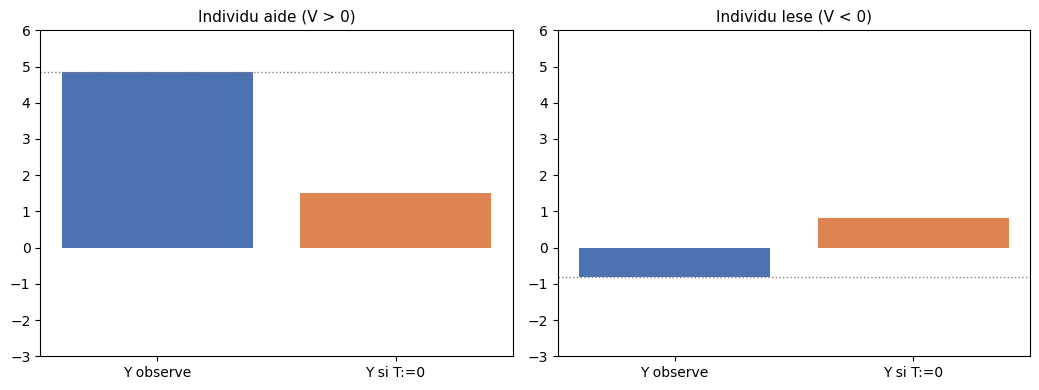

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
for axe, idx, titre in ((axes[0], idx_hi, 'Individu aide (V > 0)'), (axes[1], idx_lo, 'Individu lese (V < 0)')):
    ligne = donnees.loc[idx]
    cf = contrefactuel_individuel(scm, ligne)
    y0 = float(cf['Y'].iloc[0])
    axe.bar(['Y observe', 'Y si T:=0'], [float(ligne['Y']), y0], color=['#4C72B0', '#DD8452'])
    axe.axhline(float(ligne['Y']), color='grey', ls=':', lw=1)
    axe.set_title(titre, fontsize=11)
    axe.set_ylim(-3, 6)
plt.tight_layout()


## 6. Lecture de l'acte 1 — aider l'un, nuire l'autre

Le tableau et les barres racontent la même chose :

- **idx 532** (`V > 0`) : `Y_obs = 4.86`, mais sans le traitement il aurait eu ~`1.51`.
  Le mentorat lui a apporté **~+3.3** — proche de l'effet vrai `3.T.V = +3.27`.
- **idx 168** (`V < 0`) : `Y_obs = -0.80`, mais sans le traitement il aurait eu ~`0.81`.
  Le mentorat lui a **coûté ~-1.6** : l'écart mesuré `-1.61` rejoint l'effet vrai
  `3.T.V = -1.66` — le signe ET la magnitude sont les bons.

L'**ATE = 0** est donc vrai **et** inutile : il ne prédit ni l'un ni l'autre. Le
contrefactuel individuel, lui, prédit chacun.

## Exercice 1 — le contrefactuel inverse (étudiant non traité)

On a regardé des **traités** auxquels on arrête le traitement. Retournez le point
de vue : un étudiant **non traité** (`T < 0.4`) a `V > 0` aurait-il gagné a être
traité ?

- **Indice 1** : filtrer `donnees` sur `(T < 0.4) & (V > 0)`, en choisir un index.
- **Indice 2** : `contrefactuel_individuel(scm, ligne, variable="T", valeur=1.0)`.
- **Indice 3** : comparer `Y` contrefactuel a `Y_obs` : écart positif = il aurait gagné.
- **Étape 3** : vérifier la cohérence avec `3.V` (effet de `T:=1` vs `T:=0`).


In [6]:
# EXERCICE 1 : le contrefactuel inverse
idx_non_traite = None  # TODO etudiant : un index avec T < 0.4 et V > 0

def ecart_sous_traitement(idx, valeur=1.0):
    resultat = None  # TODO etudiant : contrefactuel_individuel + difference
    return resultat

print('Exercice a completer')


Exercice a completer


## 7. La décomposition — pourquoi la moyenne n'a rien dit

L'**ATE** est aussi la moyenne des effets individuels : `E[Y(T:=1) - Y(T:=0)]`.
Ici, chaque individu a son propre écart `Y(T_obs) - Y(T:=0) = 3.T_obs.V`. Le module
le calcule **par personne** (boucle row-wise : abduction du bruit pour CHAQUE
ligne, seule l'intervention change) :

- la **moyenne** des écarts est petite (cohérence avec un ATE proche de 0) ;
- l'**écart-type** et la moyenne des valeurs absolues sont grands : la dispersion
  est la vraie information, invisible dans l'ATE.

`ecarts_contrefactuels(scm, donnees)` retourne une `Series` indexée comme
`donnees` — c'est notre outil de décomposition.


In [7]:
ecarts = ecarts_contrefactuels(scm, donnees)
print(f'moyenne des ecarts individuels  : {ecarts.mean():+.3f}')
print(f'ecart-type des ecarts           : {ecarts.std():.3f}')
print(f'moyenne des |ecarts|           : {ecarts.abs().mean():.3f}')
print(f'min / max des ecarts           : {ecarts.min():+.2f} / {ecarts.max():+.2f}')


moyenne des ecarts individuels  : +0.331
ecart-type des ecarts           : 1.006
moyenne des |ecarts|           : 0.799
min / max des ecarts           : -1.61 / +3.35


### 7a. +0,331 ne rejoint pas l'ATE — il rejoint SA cible théorique, qui est 0,30

La section 2 annonçait un « conflit de définition » : la moyenne des écarts individuels vaut `3.E[T_obs.V] = 3.cov(T,V) = 0,3` par construction, alors que l'ATE canonique vaut `3.E[V] = 0`. La mesure ferme la boucle : **+0,331, à 0,03 de sa cible théorique 0,30**. Le point d'estimand-hygiène : ce nombre n'est pas « un ATE approximativement nul » — il est **exact pour sa propre cible**, et l'écart de 0,3 entre les deux cibles EST la confusion (les traités observés penchent vers les `V` élevés). Un estimateur de décomposition est sans biais pour sa quantité, biaisé pour l'ATE : dire « l'effet moyen est nul » et dire « la moyenne des écarts observés vaut 0,3 » sont deux énoncés vrais sur deux quantités différentes.

Même lecture pour la dispersion : l'écart-type théorique de `3.T.V` se calcule des moments du générateur (`E[V²] = 1/3`, `E[V⁴] = 1/5`, bruit `T` de 0,2) : `Var(3TV) = 9.(E[T²V²] − E[TV]²) ≈ 0,94`, soit **σ ≈ 0,97**. Le mesuré, 1,006, le dépasse d'à peine 0,04 — l'excès est le bruit d'abduction ajouté par-dessus. Deux constantes théoriques (0,30 et 0,97), deux mesures (0,331 et 1,006) : la décomposition n'improvise rien.

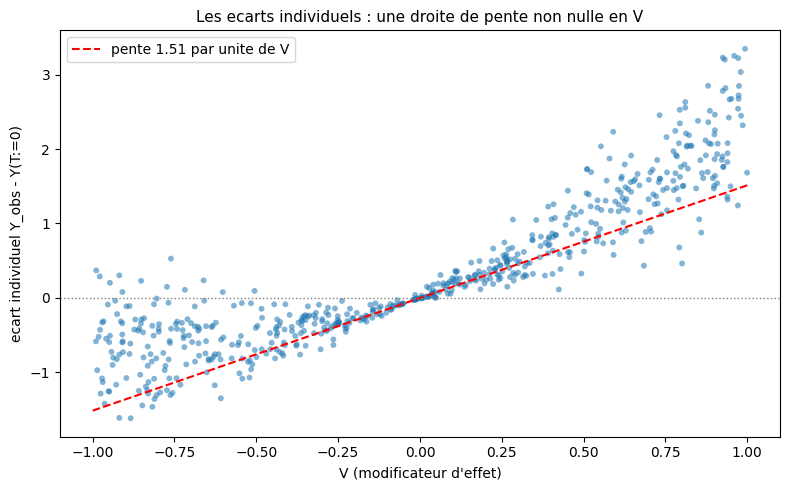

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(donnees['V'], ecarts, s=18, alpha=0.55, edgecolors='none')
pente_ecart = np.polyfit(donnees['V'], ecarts, 1)[0]
vs = np.linspace(-1, 1, 100)
ax.plot(vs, pente_ecart * vs, 'r--', lw=1.5, label=f'pente {pente_ecart:.2f} par unite de V')
ax.axhline(0, color='grey', ls=':', lw=1)
ax.set_xlabel('V (modificateur d\'effet)')
ax.set_ylabel('ecart individuel Y_obs - Y(T:=0)')
ax.set_title('Les ecarts individuels : une droite de pente non nulle en V', fontsize=11)
ax.legend()
plt.tight_layout()


## Exercice 2 — la CATE par sous-groupe, sans nouvelle boucle

La `Series ecarts` de la cellule précédente est **indexée comme `donnees`** : on
peut en déduire l'effet moyen par sous-groupe de `V` sans recalculer.

- **Indice 1** : masque = `donnees['V'].loc[ecarts.index] > 0.5` (et `< -0.5`).
- **Indice 2** : `ecarts[mask].mean()` vs `ecarts[~mask].mean()`.
- **Étape 3** : interpréter le signe de la différence en une phrase.


In [9]:
# EXERCICE 2 : CATE par sous-groupe
cate_plus = None  # TODO etudiant : moyenne des ecarts pour V > 0.5
cate_moins = None  # TODO etudiant : moyenne des ecarts pour V < -0.5

print('Exercice a completer')


Exercice a completer


## 9. Conditions de validité — et quand ne pas croire le contrefactuel

Le chiffre individuel est séduisant, il doit être **honnête**. Pour qu'il tienne :

1. **Le graphe causal est connu** (ici : toujours celui de CausalBridges-02, `V -> {T, Y}`, `T -> Y`) ;
2. **La famille de mécanismes est adéquate** : le bruit doit être additif et le
   regresseur capable de la vraie forme — polynomial degré 2 pour une interaction ;
3. **L'abduction est exacte** : le bruit individuel est parfaitement déduit de
   l'observation (il n'est pas identifié en général — ici la forme additive le
   rend identifiable).

La démonstration du point 2 : on refitte avec un mécanisme **linéaire** (`degre_y=1`, 
incapable de `T.V`) et on reprend le même individu `idx_hi`.


In [10]:
scm_lineaire = construire_scm(donnees, degre_y=1)
cf_lin = contrefactuel_individuel(scm_lineaire, donnees.loc[idx_hi])
ecart_lin = float(donnees.loc[idx_hi, 'Y']) - float(cf_lin['Y'].iloc[0])
print(f'Meme individu (idx {idx_hi}), mecanisme LINEAIRE : ecart = {ecart_lin:+.2f}')
print(f'A comparer au mecanisme polynomial      : ecart = {ecarts.loc[idx_hi]:+.2f}')
print(f'Effet vrai 3.T.V                       : {BETA_INTERACTION * donnees.loc[idx_hi, "T"] * donnees.loc[idx_hi, "V"]:+.2f}')


Fitting causal models:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node V:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node T:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node Y:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node Y: 100%|██████████| 3/3 [00:00<00:00, 246.84it/s]

Meme individu (idx 532), mecanisme LINEAIRE : ecart = +0.12
A comparer au mecanisme polynomial      : ecart = +3.35
Effet vrai 3.T.V                       : +3.27


### 9a. Le mécanisme linéaire ne dégrade pas le chiffre — il le remplace par un autre

La sortie oppose, pour le même individu idx 532 : écart **+3,35** (mécanisme polynomial) contre **+0,12** (mécanisme linéaire), effet vrai +3,27. Le mot « fragilité » est trop doux : le modèle faux ne rapproche pas du vrai, il **efface** l'hétérogénéité — l'étudiant aidé redevient « sans effet ».

Et le nombre qu'il imprime n'est pas quelconque : **+0,12 est le coefficient principal +0,111 de la régression de la section 3** — deux voies indépendantes (moindres carrés directs ; SCM à mécanisme additif linéaire) produisent le même chiffre, car c'est le meilleur effet principal linéaire, le seul qu'une forme sans interaction puisse représenter. Le contrefactuel d'un modèle mal spécifié ne raconte pas « un peu moins bien » la vérité individuelle : il répond à **une autre question** (quel est l'effet moyen principal ?) en la déguisant en question individuelle. C'est la version contrefactuelle du piège de la section 3.

## Exercice 3 — la méthode survit-elle au tirage ?

Re-générer le monde avec un autre seed (`seed=7`), refitter le SCM, re-mesurer
**moyenne** et **écart-type** des écarts individuels. La STRUCTURE (CATE linéaire
en `V`) doit survivre ; les deux étoiles, elles, changent.

- **Indice 1** : `generer_donnees(n=600, seed=7)` puis `construire_scm(...)`.
- **Indice 2** : `ecarts_contrefactuels(scm7, donnees7)`.
- **Étape 3** : comparer aux valeurs de la section 7 (moyenne ~0.3, écart-type ~1).


In [11]:
# EXERCICE 3 : stabilite de la decomposition sur un autre tirage
donnees7 = None  # TODO etudiant : generer_donnees(n=600, seed=7)
scm7 = None  # TODO etudiant : construire_scm(donnees7, degre_y=2)
ecarts7 = None  # TODO etudiant : ecarts_contrefactuels(scm7, donnees7)

print('Exercice a completer')


Exercice a completer


## 11. Synthèse — ce que le contrefactuel individuel a apporté

Trois nombres encadrent le notebook :

1. **`+3.08`** — la pente naïve : trompeuse, confondue (rung 1, sans caution) ;
2. **`+3.3` et `-1.6`** — deux individus, deux vérités opposées : l'effet moyen
   cache une CATE linéaire en `V` (rung 3) ;
3. **`~0.3` en moyenne, écart-type ~1** — l'ATE amerite le zéro, la dispersion
   est la vraie information (rung 2, par décomposition).

**Verdict honnête** : le contrefactuel individuel est exact ici parce que le
monde est connu, l'interaction polynomiale bien approchée et le bruit additive.
Sur le terrain, exiger : graphe identifié, mécanismes diagnostiqués, sensibilité
de spécification. La suite de la série (CausalBridges-04) apprendra a **découvrir** le
graphe quand il est inconnu — la dernière carte non jouée ici.

**Pour aller plus loin** : `dowhy_organs.py` (module canonique de ce notebook) —
`generer_donnees`, `construire_scm`, `contrefactuel_individuel`, 
`ecarts_contrefactuels` : importables par le prochain notebook de la série.


In [12]:
# Recapitulatif executable des trois nombres du notebook
h = int(ecarts.idxmax())
b = int(ecarts.idxmin())
print('1. pente naive confondue  : %+.3f' % pente_naive)
print('2. individu aide (idx %d)  : %+.2f   (V = %+.2f)' % (h, float(ecarts.loc[h]), donnees.loc[h, 'V']))
print('   individu lese (idx %d)  : %+.2f   (V = %+.2f)' % (b, float(ecarts.loc[b]), donnees.loc[b, 'V']))
print('3. moyenne des ecarts      : %+.3f  (ecart-type %.3f)' % (float(ecarts.mean()), float(ecarts.std())))


1. pente naive confondue  : +3.077
2. individu aide (idx 532)  : +3.35   (V = +0.99)
   individu lese (idx 6)  : -1.61   (V = -0.88)
3. moyenne des ecarts      : +0.331  (ecart-type 1.006)


### 11a. Trois nombres, trois cibles — et deux « lésés » pour le prix d'un

D'abord une curiosité du récapitulatif : l'individu lésé imprimé ici est **idx 6** (`V = −0,88`), alors que l'acte 1 mettait en scène **idx 168** (`V = −0,92`) — pour le même écart affiché `−1,61`. Deux personnes différentes, une égalité à l'arrondi : parmi les traités (`T > 0,6`), le minimum tombe sur le `V` le plus négatif ; sur l'échantillon entier, un individu faiblement traité au `V` comparable vient s'y ajouter. À n = 600, la queue de la distribution des écarts est clairsemée — les « étoiles » d'un notebook contrefactuel sont des individus tirés, pas des constantes (l'exercice 3 en fait la démonstration).

Ensuite la lecture de fond : les trois nombres du récapitulatif visent **trois cibles distinctes**. `+3,077` estime la pente naïve — une cible confondue, sans caution causale. `+0,331` estime `3.E[T_obs.V] = 0,30` — sa propre cible, pas l'ATE. `+3,35 / −1,61` estiment `3.T.V` pour deux individus — la CATE réalisée. Aucun de ces nombres n'est « le » effet du traitement : chacun est honnête contre SA cible, et la leçon transversale du notebook est là — **avant de lire un chiffre causal, nommer l'estimand qu'il poursuit**.